# Search

Directed search against random sampling on the frozen v2 scenario space.

The live cells are small and take a few minutes on a laptop CPU. Campaign-scale numbers are read from `results/v2/summary.json`. Everything here measures injected noise in one simple simulator setup, so none of it says anything about a real vehicle.

**Matching assessment**

- [Search and sampling strategy](https://niharvaghela1995.github.io/masters-thesis/assessments/s02_search_strategy.html)
- [Coverage, diversity and stopping](https://niharvaghela1995.github.io/masters-thesis/assessments/s08_coverage_stopping.html)

In [1]:
import json, sys, tempfile, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
ROOT = ROOT if (ROOT / "src").exists() else ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from stp import runner, scenario as S
from stp.v2.config import CANDIDATES, LEVELS, cfg_for
from stp.v2 import rules as RL
SPACE = CANDIDATES["A"]
SUMMARY = json.load(open(ROOT / "results/v2/summary.json"))
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
BLUE, ORANGE = "#2a78d6", "#eb6834"
def along(speeds, k1=0.012, k2=-0.004, gust=0.8):
    return [S.Params(float(v), k1, k2, gust) for v in speeds]
def reruns(p, n, level="medium", base=0):
    return [runner.run(p, base + i, LEVELS[level]) for i in range(n)]


## S02-P01: does directed search beat random sampling?

This reruns one real seed of each arm with the campaign's own code: 400 evaluations, medium noise, seed 0.

In [2]:
import multiprocessing as mp
from stp.v2.campaign import search
tmp = Path(tempfile.mkdtemp())
t = time.time()
ctx = mp.get_context("spawn")
with ctx.Pool(1) as p:
    n_nsga = p.apply(search, ("medium", "nsga2", 0, SPACE, str(tmp)))
with ctx.Pool(1) as p:
    n_rand = p.apply(search, ("medium", "random", 0, SPACE, str(tmp)))
print(f"{time.time() - t:.0f} s")
rows = {a: [json.loads(l) for l in open(tmp / f"eval_{a}_0.jsonl")] for a in ("nsga2", "random")}
saved = SUMMARY["medium"]["search"]["per_seed"]
for a in rows:
    print(a, "failures in this rerun:", sum(r["failed"] for r in rows[a]), "| saved campaign value for seed 0:", saved[a][0]["reported"])

n_gen  |  n_eval  | n_nds  |      eps      |   indicator  
     1 |       40 |      1 |             - |             -
     2 |       80 |      1 |  0.000000E+00 |             f
     3 |      120 |      1 |  0.000000E+00 |             f
     4 |      160 |      1 |  0.000000E+00 |             f
     5 |      200 |      1 |  0.0100333370 |         ideal
     6 |      240 |      1 |  0.000000E+00 |             f
     7 |      280 |      1 |  0.0101640165 |         ideal
     8 |      320 |      1 |  0.0054620047 |         ideal
     9 |      360 |      1 |  0.000000E+00 |             f
    10 |      400 |      1 |  0.000000E+00 |             f


44 s
nsga2 failures in this rerun: 329 | saved campaign value for seed 0: 329
random failures in this rerun: 103 | saved campaign value for seed 0: 103


The saved campaign, over 10 seeds per noise level:

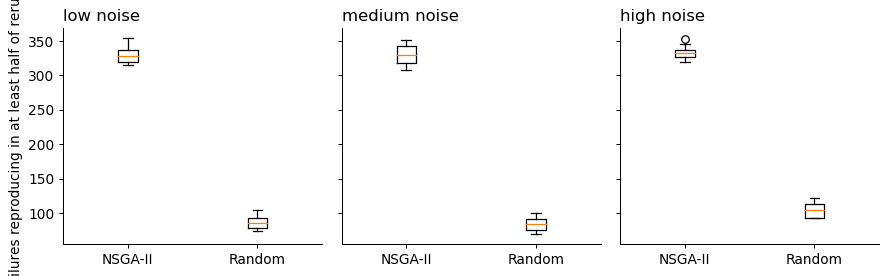

low {'reported': (330.0, 89.0, 'A12', 1.0), 'confirmed': (328.3, 86.0, 'A12', 1.0), 'cells': (33.5, 66.0, 'A12', 0.0)}
medium {'reported': (331.5, 90.5, 'A12', 1.0), 'confirmed': (329.9, 83.5, 'A12', 1.0), 'cells': (30.5, 65.5, 'A12', 0.0)}
high {'reported': (336.5, 111.5, 'A12', 1.0), 'confirmed': (332.7, 104.3, 'A12', 1.0), 'cells': (32.0, 74.0, 'A12', 0.0)}


In [3]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True)
for ax, l in zip(axs, ("low", "medium", "high")):
    P = SUMMARY[l]["search"]["per_seed"]
    ax.boxplot([[r["confirmed"] for r in P["nsga2"]], [r["confirmed"] for r in P["random"]]], labels=["NSGA-II", "Random"])
    ax.set_title(f"{l} noise", loc="left")
axs[0].set_ylabel("Failures reproducing in at least half of reruns")
plt.tight_layout(); plt.show()
for l in ("low", "medium", "high"):
    print(l, {k: (round(v["nsga2_median"], 1), round(v["random_median"], 1), "A12", v["A12"]) for k, v in SUMMARY[l]["search"]["search_vs_random"].items()})

## S02-P03: the same scenario gives different objective values

Speed is swept along a line through the controller's limit, with 20 fresh-seed reruns at each point. Search sees one of these noisy values.

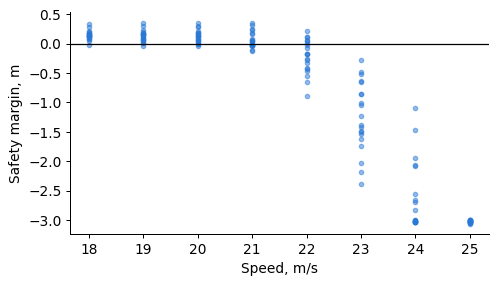

sd of margin at each speed: [0.075 0.093 0.106 0.132 0.284 0.575 0.572 0.02 ]


In [4]:
speeds = np.linspace(18, 25, 8)
data = [reruns(p, 20) for p in along(speeds)]
m = np.array([[r["margin"] for r in d] for d in data])
plt.figure(figsize=(6, 3.2))
for s, v in zip(speeds, m): plt.scatter([s] * len(v), v, s=12, color=BLUE, alpha=.5)
plt.axhline(0, color="k", lw=1); plt.xlabel("Speed, m/s"); plt.ylabel("Safety margin, m"); plt.show()
print("sd of margin at each speed:", np.round(m.std(axis=1), 3))

## S08-P02: many failures, narrow coverage

The failed evaluations from the two live runs above are binned into input cells, 5 bins per input.

In [5]:
def cells(rs):
    out = set()
    for r in rs:
        if r["failed"]:
            out.add(tuple(min(4, int(5 * (r["params"][v] - lo) / (hi - lo))) for v, lo, hi in zip(S.VARS, SPACE["xl"], SPACE["xu"])))
    return len(out)
print({a: (sum(r["failed"] for r in rows[a]), cells(rows[a])) for a in rows}, "(failures, distinct cells) in this rerun")
print({l: {a: int(np.median([r["cells"] for r in SUMMARY[l]["search"]["per_seed"][a]])) for a in ("nsga2", "random")} for l in ("low", "medium", "high")}, "median cells with a confirmed failure, saved campaign")

{'nsga2': (329, 61), 'random': (103, 85)} (failures, distinct cells) in this rerun
{'low': {'nsga2': 33, 'random': 66}, 'medium': {'nsga2': 30, 'random': 65}, 'high': {'nsga2': 32, 'random': 74}} median cells with a confirmed failure, saved campaign
